In [ ]:
#imports
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
#settings & data paths
train_dir = "chest_xray/train"
test_dir  = "chest_xray/test"

IMG_SIZE = 224 #224x224 pixels is standard for deeplearning
BATCH_SIZE = 32 # a good number to run on cpu, if using gpu, double it

In [7]:
train_datagen = ImageDataGenerator(rescale=1./255,
                                   rotation_range=15,
                                   zoom_range=0.1,
                                   horizontal_flip=True,
                                   validation_split=0.2)

train = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training")

val = train_datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation")

Found 4173 images belonging to 2 classes.
Found 1043 images belonging to 2 classes.


In [ ]:
#how many images we have in the training data set (classified)
import os
for cls in ["NORMAL", "PNEUMONIA"]:
    n = len(os.listdir(f"{train_dir}/{cls}"))
    print(cls, n)

NORMAL 1341
PNEUMONIA 3875


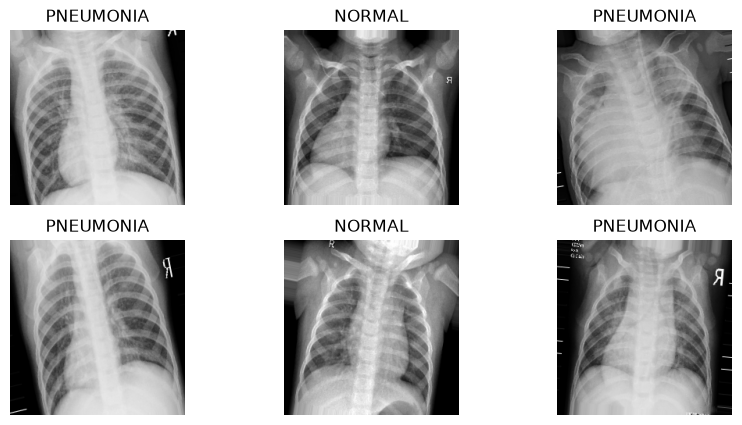

In [17]:
images, labels = next(train) # grab one batch of images + their labels from the train loader (32 photos)

plt.figure(figsize=(10, 5)) # create the overall figure, 10x5 inches in size

for i in range(6): # loop 6 times, to show 6 images
    plt.subplot(2, 3, i+1)   # place image in a 2-row x 3-col grid, at slot i+1
    plt.imshow(images[i])  # draw the i-th image
    plt.title("PNEUMONIA" if labels[i]==1 else "NORMAL")  # title = correct label (1=PNEUMONIA, 0=NORMAL)
    plt.axis("off") # hide the x/y axis ticks (cleaner look)
plt.show() # render everything on screen

In [22]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Conv2D(32, (3,3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, (3,3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

In [23]:
model.compile(optimizer="adam",
              loss="binary_crossentropy",
              metrics=["accuracy"])

history = model.fit(train,
                    validation_data=val,
                    epochs=5)
                    

Epoch 1/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 36s 271ms/step - accuracy: 0.8215 - loss: 0.4580 - val_accuracy: 0.8993 - val_loss: 0.2445
Epoch 2/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 34s 261ms/step - accuracy: 0.9010 - loss: 0.2571 - val_accuracy: 0.8984 - val_loss: 0.2835
Epoch 3/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 34s 259ms/step - accuracy: 0.9121 - loss: 0.2238 - val_accuracy: 0.9099 - val_loss: 0.2185
Epoch 4/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 34s 260ms/step - accuracy: 0.9293 - loss: 0.1917 - val_accuracy: 0.9099 - val_loss: 0.2108
Epoch 5/5
131/131 ━━━━━━━━━━━━━━━━━━━━ 35s 263ms/step - accuracy: 0.9307 - loss: 0.1847 - val_accuracy: 0.9310 - val_loss: 0.1937


In [24]:
# load the test images (normalize only — NO augmentation, we don't distort exam data)
test_datagen = ImageDataGenerator(rescale=1./255)

test = test_datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False)               # keep order fixed so predictions line up with true labels

# the real test: score the model on images it has NEVER seen
loss, accuracy = model.evaluate(test)
print("Test accuracy:", accuracy)

Found 624 images belonging to 2 classes.
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - accuracy: 0.7885 - loss: 0.5344
Test accuracy: 0.7884615659713745


## Conclusion & Interpretation

**Results.** I built a CNN from scratch to classify chest X-rays as NORMAL or PNEUMONIA. The model reached ~93% training accuracy and ~92% validation accuracy, but dropped to 79% on the unseen test set. This ~14-point gap between validation and test is a known characteristic of this dataset — the test set is distributed differently from the training data — and it's a reminder that validation scores can be optimistic.

**Handling imbalanced data.** The dataset is heavily skewed toward PNEUMONIA (~74% of images). This means plain accuracy can be misleading — a model could score high just by guessing "pneumonia" often. Metrics like precision, recall, and F1 give a more honest picture, which matters a lot in a medical context.

**Why recall matters most here.** For disease detection, a false negative (missing a real pneumonia case) is far more dangerous than a false positive (a healthy patient flagged for review). So in a real setting, I'd prioritize recall on the PNEUMONIA class over raw accuracy.

**Ethical considerations.** A model like this should be treated as a decision-support tool, not a replacement for a radiologist. Real risks include: the model learning shortcuts from a specific hospital's equipment rather than true pathology, degraded performance on populations not represented in the training data, and the danger of over-trusting an automated output. Any real deployment would require validation across diverse hospitals, clinician oversight, and clear accountability.

**Next steps.** To improve results, I would try transfer learning (e.g. MobileNetV2), apply class weights to counter the imbalance, and use EarlyStopping to train more efficiently.

**Conclusion.** This project demonstrates a full deep learning pipeline — data exploration, preprocessing, augmentation, model building, and honest evaluation — while staying realistic about the limits of AI in healthcare.